In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix,precision_score,recall_score, f1_score,roc_curve,roc_auc_score, auc, classification_report
from sklearn.preprocessing import label_binarize


In [ ]:

#loading the csv file
from google.colab import files

uploaded=files.upload()
path=list(uploaded.keys())[0]
df = pd.read_csv(path)

Saving data_updated.csv to data_updated (1).csv


In [ ]:
#class distribution (count)
df["Target"].value_counts()

,count
Target,
Graduate,2209
Dropout,1421
Enrolled,794


In [ ]:
#class distribution for proportion

df["Target"].value_counts(normalize=True)

,proportion
Target,
Graduate,0.499322
Dropout,0.321203
Enrolled,0.179476


## **Data Preprocessing**

In [ ]:

X= df.drop(columns=['Target']) #represents the input varibles
y= df['Target'].replace({'Graduate':0, 'Dropout':1, 'Enrolled':2}) #represents the target variable

/tmp/ipykernel_364/2953359189.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  y= df['Target'].replace({'Graduate':0, 'Dropout':1, 'Enrolled':2}) #represents the target variable


In [ ]:
#define categorical columns
categorical_cols = [
    "Marital status",
    "Application mode",
    "Application order",
    "Course",
    "Previous qualification",
    "Nacionality",
    "Mother's qualification",
    "Father's qualification",
    "Mother's occupation",
    "Father's occupation"
]


## **One Hot Encoding**

In [ ]:
#do one hot encoding
from sklearn.preprocessing import OneHotEncoder

X_train_pre, X_test_pre, y_train, y_test=train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
    )

encoder=OneHotEncoder(sparse_output=False, handle_unknown='ignore')

X_train_encoded=encoder.fit_transform(X_train_pre[categorical_cols])
X_test_encoded=encoder.transform(X_test_pre[categorical_cols])


X_train_df=pd.DataFrame(X_train_encoded, columns=encoder.get_feature_names_out(categorical_cols))
X_test_df=pd.DataFrame(X_test_encoded, columns=encoder.get_feature_names_out(categorical_cols))

X_train_pre = X_train_pre.reset_index(drop=True)
X_test_pre = X_test_pre.reset_index(drop=True)

X_train_en=pd.concat([X_train_pre.drop(categorical_cols, axis=1), X_train_df],axis=1)
X_test_en=pd.concat([X_test_pre.drop(categorical_cols, axis=1), X_test_df],axis=1)




## **Balancing**

In [ ]:
#balancing
from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler

#undersampling
undersampler=RandomUnderSampler(sampling_strategy='auto', random_state=42)
X_resampled_under, y_resampled_under=undersampler.fit_resample(X_train_en,y_train)

#smote method
smote=SMOTE(sampling_strategy='auto', random_state=42)
X_resampled_smote, y_resampled_smote=smote.fit_resample(X_train_en, y_train)


## **Scaling and Normalization**

In [ ]:
#normalization and splitting data into training and testing

#imbalanced data
scaler= StandardScaler()
X_train=scaler.fit_transform(X_train_en)
X_test=scaler.transform(X_test_en)

#undersampled data
scaler_under= StandardScaler()
X_train_under=scaler_under.fit_transform(X_resampled_under)

#smote data
scaler_smote= StandardScaler()
X_train_smote=scaler_smote.fit_transform(X_resampled_smote)


# **Logistic Regression Model**

In [ ]:
#train logistic regression model

model=LogisticRegression(max_iter=1000)
model.fit(X_train,y_train)

LogisticRegression(max_iter=1000)

# **Model Evaluation**

In [ ]:
#generate predictions on the test set

y_pred= model.predict(X_test)
y_pred

array([2, 1, 2, 1, 0, 1, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 2, 0, 1, 0, 0, 0,
       0, 0, 2, 0, 0, 1, 0, 2, 0, 2, 1, 1, 0, 0, 1, 0, 1, 0, 0, 1, 1, 1,
       0, 1, 0, 0, 0, 1, 1, 1, 2, 0, 0, 2, 0, 2, 0, 0, 0, 1, 1, 1, 0, 0,
       0, 2, 0, 0, 1, 2, 0, 1, 0, 1, 1, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0,
       2, 0, 0, 2, 2, 0, 1, 1, 1, 2, 1, 1, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 2, 0, 0, 0,
       0, 1, 1, 0, 0, 0, 1, 1, 1, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 1, 2,
       0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 1, 1, 0, 2, 1,
       2, 1, 1, 1, 0, 1, 1, 0, 1, 0, 0, 2, 0, 1, 1, 2, 1, 0, 1, 1, 0, 1,
       1, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 2, 0, 0, 0, 0, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 0, 0, 0, 0, 1, 1, 0, 1, 2, 1, 0, 0, 1, 0, 1, 1, 0,
       0, 0, 0, 0, 2, 0, 0, 0, 2, 0, 2, 0, 2, 0, 1, 1, 1, 0, 2, 0, 1, 0,
       1, 0, 1, 0, 0, 0, 1, 2, 1, 0, 2, 0, 1, 1, 0, 0, 1, 0, 0, 0, 1, 0,
       1, 0, 1, 0, 2, 0, 0, 1, 1, 0, 1, 0, 0, 1, 1,

In [ ]:

accuarcy=accuracy_score(y_test,y_pred)
print(f"accuracy:{round(accuarcy,2)}")

accuracy:0.76


In [ ]:
cm= confusion_matrix(y_test, y_pred)
cm

array([[392,  29,  21],
       [ 22, 226,  36],
       [ 61,  45,  53]])

In [ ]:
precision = precision_score(y_test, y_pred, average='weighted')
f"Precision: {round(precision,2)}"

'Precision: 0.74'

In [ ]:
recall=recall_score(y_test, y_pred, average='weighted')
f"Recall:{round(recall,2)}"


'Recall:0.76'

In [ ]:
f1= f1_score(y_test, y_pred, average='weighted')
f"f1 score:{round(f1,2)}"

'f1 score:0.75'

In [ ]:
#Evaluating the model
def cal_accuracy(y_test, y_pred):
  print("\nConfusion Matrix:\n", confusion_matrix(y_test,y_pred))
  print("\nAccuracy:", accuracy_score(y_test,y_pred)*100)
  print("\nClassification Report:\n", classification_report(y_test, y_pred))

cal_accuracy(y_test, y_pred)


Confusion Matrix:
 [[392  29  21]
 [ 22 226  36]
 [ 61  45  53]]

Accuracy: 75.81920903954801

Classification Report:
               precision    recall  f1-score   support

           0       0.83      0.89      0.85       442
           1       0.75      0.80      0.77       284
           2       0.48      0.33      0.39       159

    accuracy                           0.76       885
   macro avg       0.69      0.67      0.67       885
weighted avg       0.74      0.76      0.75       885



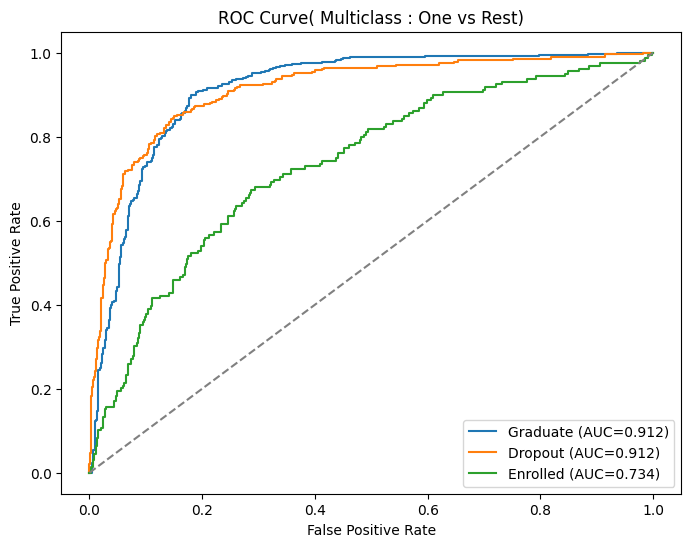

In [ ]:
plt.close('all')

#converting the test lables into a format that works for multiclass ROC
y_test_bin=label_binarize(y_test, classes=[0,1,2])


#obtain the models predicted probabilities for each class
y_prob = model.predict_proba(X_test)

#class lables
class_names=['Graduate', 'Dropout', 'Enrolled']

#setting the size for the figure
plt.figure(figsize=(8,6))

#drawing an ROC curve for each class
for i in range(3):
  #calculates how well the model seperates this class from others
  fpr, tpr, _ = roc_curve(y_test_bin[:,i], y_prob[:,i])

  #calculate the AUC score, the higher it is the better
  roc_auc= auc(fpr, tpr)

  #adding the class's curve to the plot
  plt.plot(fpr, tpr, label=f"{class_names[i]} (AUC={roc_auc:.3f})")

#plotting the random baseline (in grey)
plt.plot([0,1],[0,1], linestyle="--", color="gray")

#labels for the graph
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve( Multiclass : One vs Rest)")
plt.legend()
plt.show()
plt.close()